## Proyecto: Detección de Reseñas Falsas en E-Commerce
**Fase 2 (Ingeniería de Características y EDA) y Fase 3 (Modelado)**
Integración completa del código respetando el orden de la matriz de tareas.

In [ ]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from textblob import TextBlob
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

from scipy.sparse import hstack, csr_matrix
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


True

In [ ]:
print("--- Carga del dataset y verificación ---")
df = pd.read_csv("fake reviews dataset.csv")

columnas_utiles = ['text_', 'rating', 'label']
df = df[columnas_utiles]
df = df.dropna(subset=['text_'])
df['text_'] = df['text_'].astype(str)

df['es_fraude'] = np.where(df['label'] == 'CG', 1, 0)
print("Datos cargados correctamente. Filas:", len(df))

--- Carga del dataset y verificación ---
Datos cargados correctamente. Filas: 40432


In [ ]:
print("--- Normalización y limpieza de texto ---")
def limpiar_texto(texto):
    texto = texto.lower()
    texto = re.sub(r'<.*?>', '', texto)
    texto = re.sub(r'http\\S+|www\\S+|https\\S+', '', texto, flags=re.MULTILINE)
    texto = re.sub(r'[^\\w\\s]', '', texto)
    texto = re.sub(r'\\d+', '', texto)
    return texto

df['texto_limpio'] = df['text_'].apply(limpiar_texto)
print("Limpieza finalizada.")

--- Normalización y limpieza de texto ---
Limpieza finalizada.


In [ ]:
print("--- Tokenización, Stopwords y Lematización ---")
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def procesar_nlp(texto):
    tokens = word_tokenize(texto)
    tokens_filtrados = [w for w in tokens if w not in stop_words]
    tokens_lematizados = [lemmatizer.lemmatize(w) for w in tokens_filtrados]
    return " ".join(tokens_lematizados)

df['texto_procesado'] = df['texto_limpio'].apply(procesar_nlp)
df['longitud_palabras'] = df['texto_procesado'].apply(lambda x: len(x.split()))
print("Procesamiento NLP finalizado.")

--- Tokenización, Stopwords y Lematización ---
Procesamiento NLP finalizado.


--- Análisis Exploratorio Univariado (EDA) ---


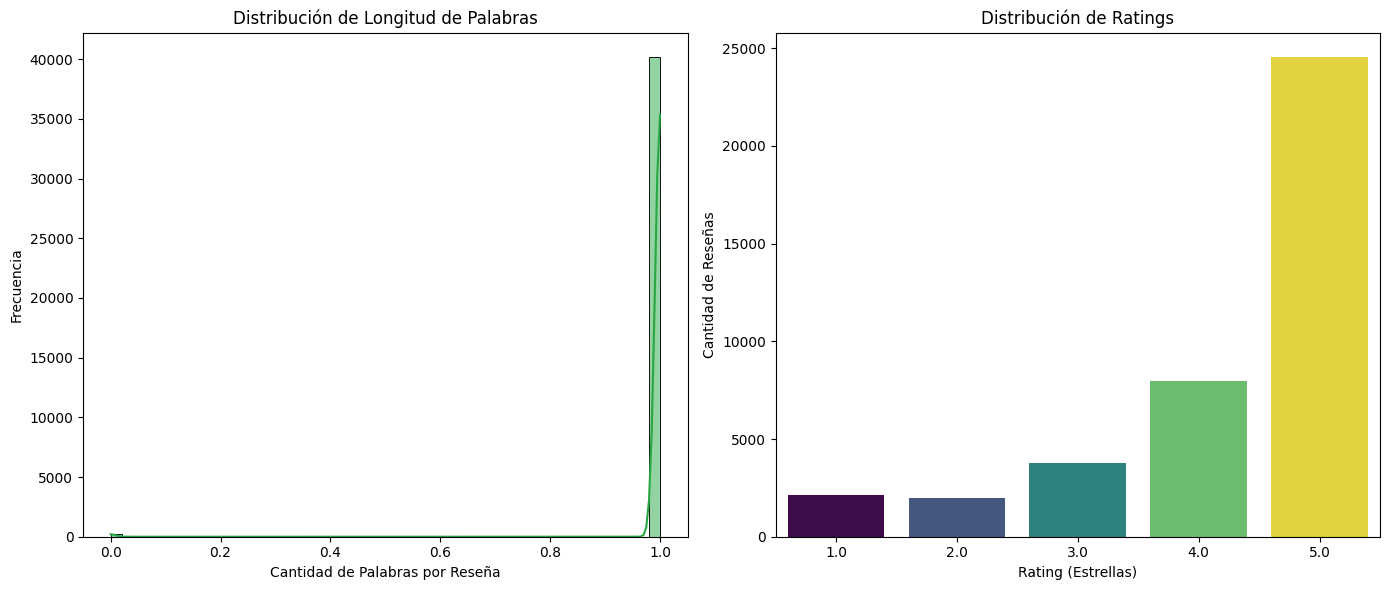

In [ ]:
print("--- Análisis Exploratorio Univariado (EDA) ---")
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.histplot(df['longitud_palabras'], bins=50, kde=True, color='#28a745')
plt.title('Distribución de Longitud de Palabras')
plt.xlabel('Cantidad de Palabras por Reseña')
plt.ylabel('Frecuencia')

plt.subplot(1, 2, 2)
sns.countplot(data=df, x='rating', palette='viridis', hue='rating', legend=False)
plt.title('Distribución de Ratings')
plt.xlabel('Rating (Estrellas)')
plt.ylabel('Cantidad de Reseñas')

plt.tight_layout()
plt.show()

In [ ]:
print("--- Extracción de Características (Exclamaciones, Mayúsculas y Léxica) ---")
def f_original(t):
    n_chars = max(len(t), 1)
    letras = [c for c in t if c.isalpha()]
    palabras = re.findall(r"[A-Za-z']+", t)
    n_pal = max(len(palabras), 1)
    may = sum(c.isupper() for c in letras)
    pal_may = sum(1 for p in palabras if len(p) > 1 and p.isupper())
    return (t.count("!") / n_chars, may / max(len(letras), 1), pal_may / n_pal)

def f_lexica(t):
    p = t.split()
    n = len(p)
    if n == 0:
        return (0.0, 0.0, 0.0, 0.0)
    cnt = pd.Series(p).value_counts()
    v = len(cnt)
    ttr = v / n
    hapax = (cnt == 1).sum() / n
    long_prom = np.mean([len(w) for w in p])
    guiraud = v / np.sqrt(n)
    return (ttr, hapax, long_prom, guiraud)

A = np.array([f_original(t) for t in df["text_"]])
B = np.array([f_lexica(t) for t in df["texto_limpio"]])

df["ratio_exclamaciones"], df["ratio_mayusculas"], df["ratio_palabras_mayus"] = A.T
df["ttr"], df["ratio_hapax"], df["long_prom_palabra"], df["guiraud"] = B.T
print("Características extraídas exitosamente.")

nuevas = ["ratio_exclamaciones", "ratio_mayusculas", "ratio_palabras_mayus",
          "ttr", "ratio_hapax", "long_prom_palabra", "guiraud"]
display(df.groupby("es_fraude")[nuevas].mean().round(4).T)

--- Extracción de Características (Exclamaciones, Mayúsculas y Léxica) ---
Características extraídas exitosamente.


es_fraude,0,1
ratio_exclamaciones,0.0022,0.0013
ratio_mayusculas,0.0388,0.0409
ratio_palabras_mayus,0.0099,0.0063
ttr,0.9985,0.9992
ratio_hapax,0.9985,0.9992
long_prom_palabra,26.6683,20.0591
guiraud,0.9985,0.9992


In [ ]:
print("--- Cálculo de Polaridad y Subjetividad ---")
df['polaridad'] = df['texto_limpio'].apply(lambda x: TextBlob(x).sentiment.polarity)
df['subjetividad'] = df['texto_limpio'].apply(lambda x: TextBlob(x).sentiment.subjectivity)
print("Sentimiento calculado.")

--- Cálculo de Polaridad y Subjetividad ---
Sentimiento calculado.


--- Matriz de Correlación entre Metadatos y Fraude ---


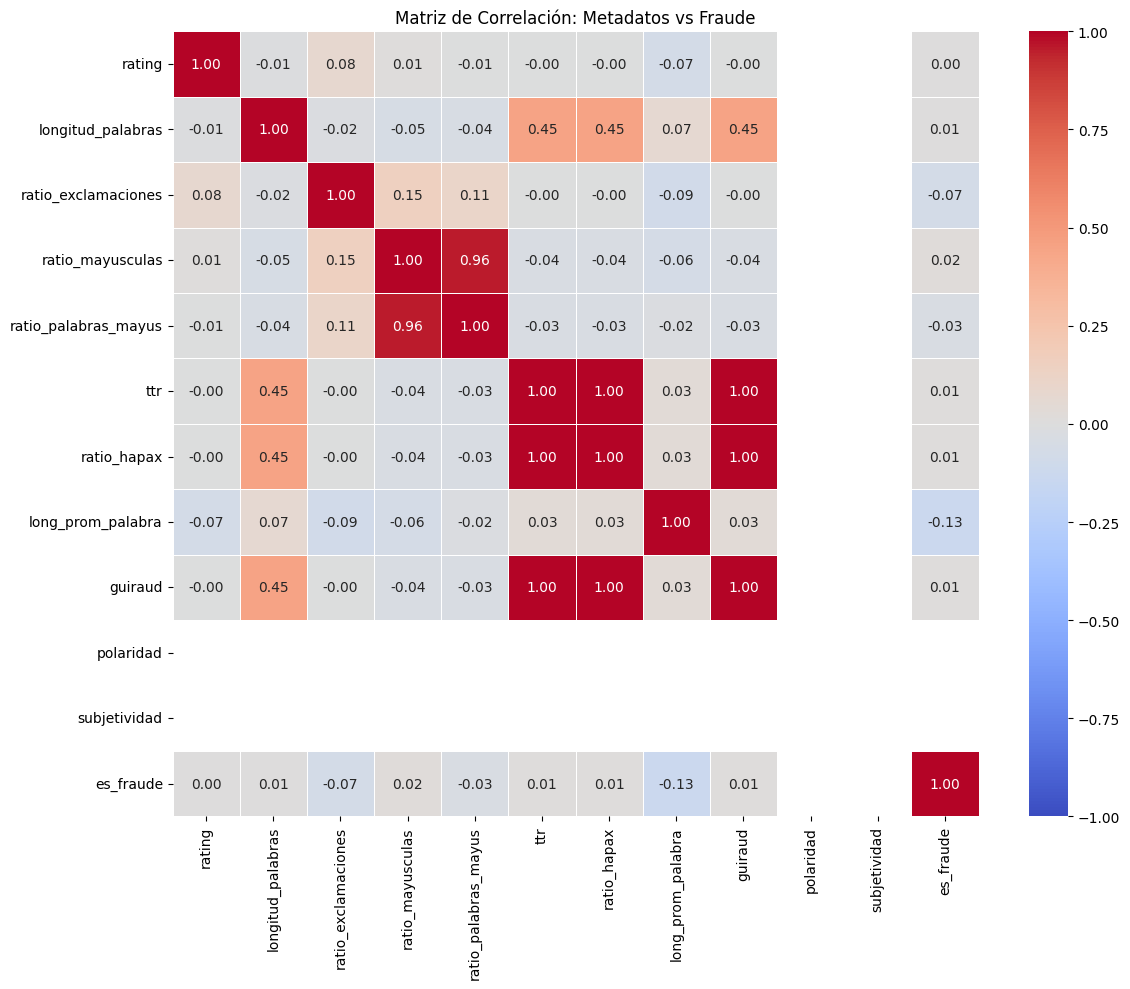

In [ ]:
print("--- Matriz de Correlación entre Metadatos y Fraude ---")
cols_numericas = [
    'rating', 'longitud_palabras', 'ratio_exclamaciones', 'ratio_mayusculas',
    'ratio_palabras_mayus', 'ttr', 'ratio_hapax', 'long_prom_palabra',
    'guiraud', 'polaridad', 'subjetividad', 'es_fraude'
]

corr_matrix = df[cols_numericas].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f", linewidths=.5)
plt.title('Matriz de Correlación: Metadatos vs Fraude')
plt.tight_layout()
plt.show()

In [ ]:
print("--- Exportación del dataset final ---")
df.to_csv("dataset_final_modelado.csv", index=False)
print("Archivo 'dataset_final_modelado.csv' guardado. ¡Fase 2 completada!")

--- Exportación del dataset final ---
Archivo 'dataset_final_modelado.csv' guardado. ¡Fase 2 completada!


In [ ]:
print("--- Fase 3: Entrenamiento de Modelos (Base vs Enriquecido) ---")
base = ["rating", "longitud_palabras"]
nuevas = ["ratio_exclamaciones", "ratio_mayusculas", "ratio_palabras_mayus",
          "ttr", "ratio_hapax", "long_prom_palabra", "guiraud", "polaridad", "subjetividad"]

# División de datos (Train / Test)
train, test = train_test_split(df, test_size=0.2, stratify=df["es_fraude"], random_state=42)
ytr, yte = train["es_fraude"].values, test["es_fraude"].values

# Vectorización TF-IDF
tfidf = TfidfVectorizer(max_features=2000, ngram_range=(1, 2), min_df=5)
Ttr = tfidf.fit_transform(train["texto_procesado"])
Tte = tfidf.transform(test["texto_procesado"])

def matrices(cols):
    sc = StandardScaler()
    return (hstack([Ttr, csr_matrix(sc.fit_transform(train[cols]))]).tocsr(),
            hstack([Tte, csr_matrix(sc.transform(test[cols]))]).tocsr())

def modelos():
    return {
        "Regresión Logística": (LogisticRegression(max_iter=1000), False),
        "Random Forest": (RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42), False),
        "Gradient Boosting": (HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, random_state=42), True),
    }

res = []
# Entrenamiento y evaluación
for conjunto, cols in [("Original", base), ("Original + nuevas", base + nuevas)]:
    Xtr, Xte = matrices(cols)
    for n, (m, dense) in modelos().items():
        a, b = (Xtr.toarray().astype("float32"), Xte.toarray().astype("float32")) if dense else (Xtr, Xte)
        m.fit(a, ytr)
        p = m.predict(b)
        pr = m.predict_proba(b)[:, 1]
        res.append(dict(conjunto=conjunto, modelo=n, accuracy=accuracy_score(yte, p),
                        precision=precision_score(yte, p), recall=recall_score(yte, p),
                        f1=f1_score(yte, p), roc_auc=roc_auc_score(yte, pr)))
        print(f"Entrenado: {conjunto} - {n}")

resultados = pd.DataFrame(res).round(4)

# Imprimir la tabla de métricas finales
display(resultados)

--- Fase 3: Entrenamiento de Modelos (Base vs Enriquecido) ---
Entrenado: Original - Regresión Logística
Entrenado: Original - Random Forest
Entrenado: Original - Gradient Boosting
Entrenado: Original + nuevas - Regresión Logística
Entrenado: Original + nuevas - Random Forest
Entrenado: Original + nuevas - Gradient Boosting


,conjunto,modelo,accuracy,precision,recall,f1,roc_auc
0,Original,Regresión Logística,0.5393,0.5686,0.3250,0.4136,0.5366
1,Original,Random Forest,0.5364,0.5679,0.3042,0.3962,0.5272
2,Original,Gradient Boosting,0.5265,0.5771,0.1981,0.2950,0.5276
3,Original + nuevas,Regresión Logística,0.5932,0.5998,0.5597,0.5791,0.6406
4,Original + nuevas,Random Forest,0.6047,0.6058,0.5991,0.6024,0.6458
5,Original + nuevas,Gradient Boosting,0.6540,0.6255,0.7673,0.6892,0.7066
